# GA figures

Generates the paper figures from the runs in `runs_dir` and writes them to `figures_dir`. The fits use this folder's
`src/` and `data/`, so the RSD data are the updated ones. Every result in `runs_dir`
is picked up, so when more tasks arrive, re-run the notebook from the top. The polished fits are recomputed
automatically, because their cache is keyed to the exact set of run winners.

The plotting packages are not in this folder's `Project.toml` (the cluster environment), so the first code cell
activates `plotting_env/`, which adds CairoMakie, LaTeXStrings and MathTeXEngine. Instantiate it once with
`julia --project=plotting_env -e 'using Pkg; Pkg.instantiate()'`.

| Figure | Cell |
|---|---|
| `chi2_evolution.pdf` | χ² evolution |
| `mu_G_game.pdf` | `GAME` $\mu_G(z)$ |
| `F_and_U_game.pdf` | `GAME` $F$ and $U$ panels |
| `eos_game_desi.pdf` | `GAME` $w(z)$ with the CPL and binned posteriors |
| `H_game.pdf` | $H(z)/(1+z)$: ΛCDM, CPL and the GA |

### Imports and configuration

In [17]:
using Pkg
Pkg.activate(joinpath(@__DIR__, "plotting_env"))   # cluster Project.toml plus the plotting packages
include(joinpath(@__DIR__, "src", "run_ga.jl"))
using CairoMakie
# Inline display only: show the raw PNG, drawn at 3× the figure size. The saved PDFs are not affected.
CairoMakie.activate!(type="png", px_per_unit=3)
CairoMakie.enable_only_mime!(MIME"image/png"())
using LaTeXStrings
using MathTeXEngine
using Printf

# Everything that changes between sets of runs
runs_dir = joinpath("runs", "grid_main")
figures_dir = "figures"
game_cache_path = joinpath(runs_dir, "game_polished.h5")
mkpath(figures_dir)

  Activating project at `~/Desktop/Code/GA_ST/Final_version/plotting_env`


"figures"

In [18]:
# Plotting constants for publication
const UNITS_PER_INCH = 96.0
const UNITS_PER_POINT = 4.0 / 3.0
const SCALE = 1.0

width_inches::Float64 = 3.375
height_inches::Float64 = width_inches * 0.7#2.65
axis_label_pt::Float64 = 10.0 * UNITS_PER_POINT
tick_label_pt::Float64 = 9.0 * UNITS_PER_POINT
legend_pt::Float64 = 9.0 * UNITS_PER_POINT
annotation_pt::Float64 = 8.0 * UNITS_PER_POINT
panel_label_pt::Float64 = 10.0 * UNITS_PER_POINT
line_pt::Float64 = 1.2 * UNITS_PER_POINT
reference_line_pt::Float64 = 0.95 * UNITS_PER_POINT
axis_line_pt::Float64 = 0.55 * UNITS_PER_POINT
tick_size_pt::Float64 = 3.5 * UNITS_PER_POINT
tick_width_pt::Float64 = axis_line_pt
grid_line_pt::Float64 = 0.40 * UNITS_PER_POINT
marker_pt::Float64 = 4.5 * UNITS_PER_POINT
grid::Symbol = :major
show_titles::Bool = false
raster_dpi::Int = 300
palette::Vector{String} = ["#0072B2", "#E69F00", "#D55E00", "#CC79A7",
    "#56B4E9", "#000000", "#F0E442"]
reconstructed_color::String = "#0072B2"
reference_color::String = "#222222"
invalid_color::String = "#D55E00"
background_color::String = "#FFFFFF"
band_alpha::Float64 = 0.12
margins_pt::Float64 = 6.0 * UNITS_PER_POINT
panel_gap_pt::Float64 = 5.0 * UNITS_PER_POINT
panel_padding_pt = 8.0 * UNITS_PER_POINT
label_padding_pt = 5.0 * UNITS_PER_POINT
legend_margin_pt = 5.0 * UNITS_PER_POINT
legend_padding_pt = 6.0 * UNITS_PER_POINT


# ── Fonts matching the paper ────────────────────────────────────────────────────────────────────
# Keep it before the theme: texfont() reads the family set here.
#
# draft.tex is compiled with pdflatex + newtxtext/newtxmath. Each glyph type below is taken from the
# font the paper itself uses for it (read off the paper's PDF):
#   text, digits, ( ), tick labels   TeX Gyre TermesX          newtxtext
#   Latin math letters (z, w, F, U)  TeX Gyre TermesX Italic   same Times italic design as newtxmath's letters
#   lowercase Greek (μ, φ, χ, ...)   NewTXMI (padded, below)   newtxmath
#   =  Δ  Λ                          txmiaX                    newtxmath
#   −  +  ≡                          txsys                     newtxmath
#   \texttt (GAME)                   txtt                      newtxtext
# All files come from the TeX Live tree via kpsewhich, except fonts/NewTXMI-padded.otf. Anything that cannot be
# found keeps MathTeXEngine's own choice and is reported, so the cell never fails.

kpse(file) = Sys.which("kpsewhich") === nothing ? "" :
    String(readchomp(ignorestatus(`kpsewhich $file`)))

paper_font_paths = Dict(
    :regular    => kpse("TeXGyreTermesX-Regular.otf"),
    :italic     => kpse("TeXGyreTermesX-Italic.otf"),
    :bold       => kpse("TeXGyreTermesX-Bold.otf"),
    :bolditalic => kpse("TeXGyreTermesX-BoldItalic.otf"),
    :math       => kpse("STIXTwoMath-Regular.otf"),   # only for symbols not mapped below
)
# Greek from NewTXMI with the side bearings and widths of newtxmath's virtual font ntxmi.vf, which MathTeXEngine cannot
# read (fonts/make_padded_newtxmi.py builds it). With the raw NewTXMI.pfb the Greek is set tighter than in the paper,
# and the tail of χ runs under a preceding Δ.
padded_newtxmi = joinpath(@__DIR__, "fonts", "NewTXMI-padded.otf")
isfile(padded_newtxmi) ||
    @warn "$padded_newtxmi not found (run python3 fonts/make_padded_newtxmi.py); Greek uses the raw NewTXMI.pfb"
newtx_files = Dict(:greek => isfile(padded_newtxmi) ? padded_newtxmi : kpse("NewTXMI.pfb"),
    :mia => kpse("txmiaX.pfb"), :sys => kpse("txsys.pfb"))
paper_tt_font = kpse("txtt.pfb")   # \texttt of the paper; MathTeXEngine has no \texttt

if all(isfile, values(paper_font_paths))
    # 1. Brackets. MathTeXEngine 0.6.x draws ( ) [ ] { } | from its *built-in* default math font
    #    (New Computer Modern), whatever the font family says. Point that default at TermesX, the font
    #    of the paper's brackets. Internal, unexported setting: re-check after updating MathTeXEngine.
    MathTeXEngine._default_fonts[:math] = paper_font_paths[:regular]

    # 2. Greek and operators from newtx's own fonts, looked up by glyph name. The fonts name Greek by
    #    code point: NewTXMI's math italics are "u1D6FC" (𝛼) ... "u1D71B" (𝜛), txmiaX's upright capitals
    #    "uni0394" (Δ), "uni039B" (Λ). Each name is the glyph newtxmath's virtual font ntxmi.vf draws for
    #    that command: \varphi is "u1D711" (curly), \phi is "u1D719"; MathTeXEngine turns \varphi into φ
    #    and \phi into ϕ, \epsilon into ϵ and \varepsilon into ε.
    newtx_glyph_names = Dict{Char, Tuple{Symbol, Vector{String}}}(
        'α' => (:greek, ["u1D6FC"]),  'β' => (:greek, ["u1D6FD"]),   'γ' => (:greek, ["u1D6FE"]),
        'δ' => (:greek, ["u1D6FF"]),  'ϵ' => (:greek, ["u1D716"]),   'ε' => (:greek, ["u1D700"]),
        'ζ' => (:greek, ["u1D701"]),  'η' => (:greek, ["u1D702"]),   'θ' => (:greek, ["u1D703"]),
        'ϑ' => (:greek, ["u1D717"]),  'ι' => (:greek, ["u1D704"]),   'κ' => (:greek, ["u1D705"]),
        'λ' => (:greek, ["u1D706"]),  'μ' => (:greek, ["u1D707"]),   'ν' => (:greek, ["u1D708"]),
        'ξ' => (:greek, ["u1D709"]),  'π' => (:greek, ["u1D70B"]),   'ϖ' => (:greek, ["u1D71B"]),
        'ρ' => (:greek, ["u1D70C"]),  'ϱ' => (:greek, ["u1D71A"]),   'σ' => (:greek, ["u1D70E"]),
        'ς' => (:greek, ["u1D70D"]),  'τ' => (:greek, ["u1D70F"]),   'υ' => (:greek, ["u1D710"]),
        'ϕ' => (:greek, ["u1D719"]),  'φ' => (:greek, ["u1D711"]),   'χ' => (:greek, ["u1D712"]),
        'ψ' => (:greek, ["u1D713"]),  'ω' => (:greek, ["u1D714"]),
        '=' => (:mia, ["equal"]),     'Δ' => (:mia, ["uni0394"]),    'Λ' => (:mia, ["uni039B"]),
        '−' => (:sys, ["minus"]),     '+' => (:sys, ["plus"]),       '≡' => (:sys, ["equivalence"]),
    )

    function newtx_glyph(path, names)
        isfile(path) || return nothing
        font = MathTeXEngine.load_font(path)
        for name in names
            id = MathTeXEngine.glyph_index(font, name)
            id != 0 && return (path, Int(id))
        end
        return nothing
    end

    paper_special_chars = Dict{Char, Tuple{String, Int}}()
    unresolved = Char[]
    for (char, (kind, names)) in newtx_glyph_names
        glyph = newtx_glyph(newtx_files[kind], names)
        glyph === nothing ? push!(unresolved, char) : (paper_special_chars[char] = glyph)
    end

    # Fallback for any lowercase Greek not found in NewTXMI: STIX Two Math italics, as before
    stix = MathTeXEngine.load_font(paper_font_paths[:math])
    stix_italic = merge(Dict('α' + i => Char(0x1D6FC + i) for i in 0:24),
        Dict('ϵ' => '𝜖', 'ϑ' => '𝜗', 'ϰ' => '𝜘', 'ϕ' => '𝜙', 'ϱ' => '𝜚', 'ϖ' => '𝜛'))
    for char in unresolved
        haskey(stix_italic, char) &&
            (paper_special_chars[char] = (paper_font_paths[:math], Int(MathTeXEngine.glyph_index(stix, stix_italic[char]))))
    end
    isempty(unresolved) ||
        @warn "Not found in the newtx fonts (kept STIX Two Math): $(join(sort(unresolved), ' '))"

    set_texfont_family!(FontFamily(paper_font_paths; special_chars=paper_special_chars))
else
    @warn "TeX Gyre TermesX or STIX Two Math not found with kpsewhich; keeping Computer Modern"
    set_texfont_family!()
end

# Define styles
vscode_theme = Theme(
    # Figure environment
    size = (SCALE * UNITS_PER_INCH * width_inches, SCALE * UNITS_PER_INCH * height_inches),
    font = texfont(),
    fontsize = SCALE * axis_label_pt,
    figure_padding = SCALE * panel_padding_pt,

    Axis = (
        xlabelsize = SCALE * axis_label_pt,
        ylabelsize = SCALE * axis_label_pt,
        xticklabelsize = SCALE * tick_label_pt,
        yticklabelsize = SCALE * tick_label_pt,
        xlabelpadding = SCALE * label_padding_pt,
        ylabelpadding = SCALE * label_padding_pt,

        spinewidth = SCALE * axis_line_pt,
        xticksize = SCALE * tick_size_pt,
        yticksize = SCALE * tick_size_pt,
        xtickwidth = SCALE * tick_width_pt,
        ytickwidth = SCALE * tick_width_pt,

        xminorticksvisible = true,
        yminorticksvisible = true,
        xminorticksize = 0.5 * SCALE * tick_size_pt,
        yminorticksize = 0.5 * SCALE * tick_size_pt,
        xminortickwidth = SCALE * tick_width_pt,
        yminortickwidth = SCALE * tick_width_pt,

        # Two-sided ticks centred on the spine's centre line. Makie measures ticks from the spine's outer edge,
        # so tickalign = 0.5 would leave them half a spine width outward; shift by that half width
        xtickalign = 0.5 + 0.5 * axis_line_pt / tick_size_pt,
        ytickalign = 0.5 + 0.5 * axis_line_pt / tick_size_pt,
        xminortickalign = 0.5 + 0.5 * axis_line_pt / (0.5 * tick_size_pt),
        yminortickalign = 0.5 + 0.5 * axis_line_pt / (0.5 * tick_size_pt),
        xminorticks = IntervalsBetween(5),   # 4 minor ticks on the z axis: every 0.1 between majors 0.5 apart

        xlabelfont = texfont(),
        ylabelfont = texfont(),
        xticklabelfont = texfont(),
        yticklabelfont = texfont(),
        
    ),

    Lines = (
        linewidth = SCALE * line_pt,
    ),

    Legend = (
        framevisible = true,
        labelsize = SCALE * legend_pt,
        orientation = :vertical,
        patchlabelgap = SCALE * 5,
        patchsize = (SCALE * 20, SCALE * 15),
        margin = (SCALE * legend_margin_pt, SCALE * legend_margin_pt,
        SCALE * legend_margin_pt, SCALE * legend_margin_pt),
        padding = (SCALE * legend_padding_pt, SCALE * legend_padding_pt,
        0 * SCALE * legend_padding_pt, 0 * SCALE * legend_padding_pt),
        framewidth = SCALE * axis_line_pt,
        labelfont=texfont()
    )
);

set_theme!(vscode_theme)

### Load the runs

In [19]:
# Runs still on the cluster have no result.h5 yet. A run stopped at the wall-time limit has one, but it is partial
# until it is resumed (status "interrupted"), so only completed runs are used.
result_paths = String[]
for (dir, _, files) in walkdir(runs_dir)
    "result.h5" in files || continue
    status = TOML.parsefile(joinpath(dir, "metadata.toml"))["status"]
    status == "completed" ? push!(result_paths, joinpath(dir, "result.h5")) : println("Skipping ($status): ", dir)
end

sort!(result_paths)  # Stable index-to-path mapping
isempty(result_paths) && error("no completed runs in $runs_dir")
println("Loading ", length(result_paths), " completed runs from ", runs_dir)

function load_plot_result(path::String)
    _verify_checksum(path)
    _validate_h5(path, "result")

    run_dir = dirname(abspath(path))
    config = config_from_dict(TOML.parsefile(joinpath(run_dir, "config.toml")))
    metadata = TOML.parsefile(joinpath(run_dir, "metadata.toml"))

    h5open(path, "r") do file
        RunResult(
            config,
            metadata,
            only(read_candidates(file["best_description_length"])),
            only(read_candidates(file["best_chi2"])),
            FittedCandidate[],  # archives are not needed here
            FittedCandidate[],
            read_history(file["history"]),
        )
    end
end

results = load_plot_result.(result_paths)
histories = generation_history.(results)
best_individuals = [
    best_candidate(result; criterion=:chi2)
    for result in results
]

generations = [
    [row.generation for row in history]
    for history in histories
]
chi2_evolution = [
    [row.global_best_chi2 for row in history]
    for history in histories
]

# Rank runs by their final best χ².
ranking = sortperm([candidate.chi2 for candidate in best_individuals])
best_run_index = ranking[1]

result_nolocal_path = result_paths[best_run_index]
result_nolocal = results[best_run_index]
best_nolocal = best_individuals[best_run_index]
println("Best run: ", result_nolocal_path)
println("Best χ²: ", best_nolocal.chi2)
println("F(Φ) = ", best_nolocal.individual.F)
println("U(Φ) = ", best_nolocal.individual.U)

println("Fitted parameters:")
for (name, value) in zip(best_nolocal.param_names, best_nolocal.best_params)
    println("  ", name, " = ", value)
end
history_nolocal = histories[best_run_index]
generation_nolocal = generations[best_run_index]
chi2_nolocal = chi2_evolution[best_run_index]

Loading 64 completed runs from runs/grid_main
Best run: runs/grid_main/task_63/20261111T112248Z_6ac8ecad-c492-4a5b-8c0c-3e12f28c1f8c/result.h5
Best χ²: 1571.7419409129905
F(Φ) = ((x1 * x1) * 0.8823362800743394) + (((x1 * -0.9946252131574695) * exp(x1)) + exp(x1))
U(Φ) = ((x1 * x1) * -0.6362216761187258) - ((x1 * x1) * x1)
Fitted parameters:
  Om0 = 0.2933850923361176
  h = 0.698644998235164
  M_nuisance = -19.4423010799389
  sigma8_0 = 0.8055028872398142
  Ob0 = 0.045897341606191196


2000-element Vector{Float64}:
 1582.6037918819404
 1578.9020913997854
 1578.3277922795467
 1578.3277922795467
 1578.3277922795467
 1578.2642233870888
 1577.4408044211978
 1576.9436176512374
 1576.9436176512374
 1576.9436176512374
    ⋮
 1571.7419409129905
 1571.7419409129905
 1571.7419409129905
 1571.7419409129905
 1571.7419409129905
 1571.7419409129905
 1571.7419409129905
 1571.7419409129905
 1571.7419409129905

In [20]:
function fit_lcdm_gptv2(result::RunResult)
    config = result.config

    F = Node(Float64; val=1.0)
    U = Node(Float64; val=0.0)
    individual = Individual(F, U, 0, compute_complexity(F, U))

    F_func, U_func = compile_tree_lcdm()
    p = CosmoParams(0.295, 0.0, F_func, U_func)
    cache = setup_cosmo_cache(p, 0.685, config.physics.dphi_initial)

    saved = config.minimizer
    settings = MinimizeSettings(
        Inf, saved.g_tol, 1,
        saved.fisher_fd_factor, saved.fisher_negative_tol,
        saved.invalid_objective, saved.rejection_objective,
        saved.recovery_enabled, saved.recovery_max_probes,
        saved.recovery_time_fraction,
    )
    penalty_settings = PenaltySettings(mode=:functional_only)

    fit = optimize_individual!(
        individual,
        load_likelihoods(config.ga.likelihoods),
        cache;
        settings=settings,
        penalty_settings=penalty_settings,
    )
    fit.accepted || error("ΛCDM fit was rejected: $(fit.termination)")

    return fitted_candidate(fit, penalty_settings)
end

candidate_lcdm = fit_lcdm_gptv2(result_nolocal)
background_lcdm = reconstruct_background(candidate_lcdm, result_nolocal.config)

chi2_LCDM = candidate_lcdm.chi2
U_lcdm = background_lcdm.p.U0   # constant potential of the ΛCDM fit (3Ω_Λ in units of H0²)
gen_best = last(generation_nolocal)
chi2_best = best_nolocal.chi2

# χ² of each dataset: ΛCDM against the best individual
@assert candidate_lcdm.likelihood_names == best_nolocal.likelihood_names
@printf("  %-26s %10s %10s %10s\n", "", "ΛCDM", "Best", "Δχ²")
for (name, lcdm, best) in zip(candidate_lcdm.likelihood_names, candidate_lcdm.likelihood_chi2, best_nolocal.likelihood_chi2)
    @printf("  %-26s %10.4f %10.4f %+10.4f\n", name, lcdm, best, best - lcdm)
end
@printf("  %-26s %10.4f %10.4f %+10.4f\n", "Total", chi2_LCDM, chi2_best, chi2_best - chi2_LCDM)

PantheonPlus+SH0ES initialized. Total SN: 1701. Cepheid anchors: 77
DESI DR2 BAO initialized. 13 data points.
Planck 2018 (Zhai et. al.) initialized
Redshift Space Distortion initialized. 20 points.
PPN gamma-1 initialized: 2.1e-5 +/- 2.3e-5 (Cassini)
LLR Gdot/G initialized: -5.0e-15 +/- 9.6e-15 (1/yr)
BBN G_BBN/G_0 initialized: 0.99 +/- 0.03 (dimensionless)
                                   ΛCDM       Best        Δχ²
  PantheonPlusSH0ES_muG       1552.0308  1537.9502   -14.0806
  DESI_BAO                      10.6704    12.1320    +1.4616
  PlanckCompressed_Zhai2018      7.3588     0.0854    -7.2734
  GrowthRateLikelihood          17.1016    16.3962    -0.7054
  PPNGammaLikelihood             0.8336     0.8341    +0.0004
  LLRGdotLikelihood              0.2713     0.0003    -0.2710
  BBNGLikelihood                 0.1111     4.3438    +4.2327
  Total                       1588.3776  1571.7419   -16.6357


In [21]:
function w_ST(bg::Background, z::Real)
    N = -log1p(z)
    Φ, dΦ_dN = Φ_and_dΦ(bg, z)
    d = compute_field_dynamics(bg.p, bg.Or0, N, Φ, dΦ_dN)

    ρ_ST = d.q - d.rho_m - d.rho_r
    p_ST = -d.q * (1.0 + 2.0 * d.s / 3.0) - d.rho_r / 3.0

    iszero(ρ_ST) ? NaN : p_ST / ρ_ST
end

"""
    field_functions(bg, z) -> (F, F_Φ², U_total)

Coupling `F(Φ(z))`, squared slope `(dF/dΦ)²(Φ(z))` and total potential `U0 + U(Φ(z))` (in units of H0²)
along the solution in `bg`. Unlike `F(Φ)` and `U(Φ)`, these do not depend on how the field is shifted or
reflected.

Generated with Claude Opus 5.5.
"""
function field_functions(bg::Background, z::Real)
    Φ, _ = Φ_and_dΦ(bg, z)
    F, F_Φ, _ = bg.p.F_funcs(Φ)
    return F, F_Φ^2, bg.p.U0 + bg.p.U_funcs(Φ)[1]
end

field_functions

### CPL and binned posteriors

Newest `cpl_*.h5` and `binned_*.h5` in `binning/chains/`, sampled by `binning/python/run_nautilus.py` in the main project (not copied here).

These chains use only the four cosmological likelihoods, while the GA also fits the local tests of gravity (Cassini,
LLR, BBN). GR sits slightly off the centre of all three bounds, so ΛCDM pays a fixed χ² for them. CPL has $F = 1$ and
pays exactly the same amount, so `chi2_CPL` below adds the ΛCDM values of the likelihoods missing from the chain. Note
that `chain.map_chi2` itself does not include them.

In [22]:
include(joinpath(@__DIR__, "binning", "WzBinning.jl"))
include(joinpath(@__DIR__, "binning", "WzPlots.jl"))
using .WzBinning: load_wz_chain, param_summary, w_quantiles   # selective: the GA also defines H, E, ... in Main
using .WzPlots: plot_w_cpl!, plot_w_binned!, errorbar_legend_handle

"""
    newest_wz_chain(model) -> String

Newest `binning/chains/<model>_<UTCstamp>.h5` written by `run_nautilus.py`. Labelled runs such as
`validation_cpl_*` are skipped.

Generated with Claude Opus 5.5.
"""
function newest_wz_chain(model::AbstractString)
    dir = joinpath(@__DIR__, "binning", "chains")
    files = filter(f -> startswith(f, model * "_") && endswith(f, ".h5"), readdir(dir))
    isempty(files) && error("no $(model)_*.h5 in $dir; run binning/python/run_nautilus.py --model $model")
    return joinpath(dir, maximum(files))
end

cpl_chain = load_wz_chain(newest_wz_chain("cpl"))
binned_chain = load_wz_chain(newest_wz_chain("binned"))

for chain in (cpl_chain, binned_chain)
    println(chain)
    for p in param_summary(chain)
        @printf("  %-11s %9.4f ± %.4f   68%%: [%8.4f, %8.4f]   MAP %9.4f\n",
            p.name, p.mean, p.std, p.lo68, p.hi68, p.map)
    end
end

# χ² of the chains on the GA's likelihoods: add what ΛCDM (F = 1, like CPL and the binned w) pays for the local tests
local_gravity = (:PPNGammaLikelihood, :LLRGdotLikelihood, :BBNGLikelihood)
Δχ2_chain_offset = sum(c for (name, c) in zip(candidate_lcdm.likelihood_names, candidate_lcdm.likelihood_chi2)
    if name in local_gravity)
chi2_CPL = cpl_chain.map_chi2 + Δχ2_chain_offset
chi2_binned = binned_chain.map_chi2 + Δχ2_chain_offset
@printf("Local-gravity χ² added to the chains: %.4f\n", Δχ2_chain_offset)
@printf("χ²_CPL = %.4f (Δχ² = %+.2f)   χ²_binned = %.4f (Δχ² = %+.2f)\n",
    chi2_CPL, chi2_CPL - chi2_LCDM, chi2_binned, chi2_binned - chi2_LCDM)

# Sizes of the binned markers, bars and violins in the publication theme
binned_style = (linewidth=0.75 * SCALE * line_pt, whiskerwidth=SCALE * 4, markersize=SCALE * marker_pt,
    violin_strokewidth=0.5 * SCALE * line_pt)

WzChain(cpl

, 14200 weighted points (n_eff 10061) × 7 parameters, χ²_MAP = 1576.52)
  Om0            0.2994 ± 0.0050   68%: [  0.2944,   0.3043]   MAP    0.2992
  h              0.6896 ± 0.0054   68%: [  0.6842,   0.6950]   MAP    0.6897
  M_nuisance   -19.3816 ± 0.0128   68%: [-19.3942, -19.3690]   MAP  -19.3816
  sigma8_0       0.7955 ± 0.0264   68%: [  0.7697,   0.8213]   MAP    0.7954
  Ob0            0.0473 ± 0.0008   68%: [  0.0465,   0.0480]   MAP    0.0473
  w0            -0.8714 ± 0.0548   68%: [ -0.9261,  -0.8173]   MAP   -0.8762
  wa            -0.6468 ± 0.2239   68%: [ -0.8687,  -0.4226]   MAP   -0.6223
WzChain(binned, 14400 weighted points (n_eff 10049) × 9 parameters, χ²_MAP = 1571.785)
  Om0            0.2999 ± 0.0049   68%: [  0.2951,   0.3048]   MAP    0.2995
  h              0.6908 ± 0.0053   68%: [  0.6855,   0.6961]   MAP    0.6906
  M_nuisance   -19.3834 ± 0.0126   68%: [-19.3962, -19.3709]   MAP  -19.3841
  sigma8_0       0.7992 ± 0.0264   68%: [  0.7728,   0.8257]   MAP    0

(linewidth = 1.2, whiskerwidth = 4.0, markersize = 6.0, violin_strokewidth = 0.7999999999999999)

### $\chi^2$ evolution

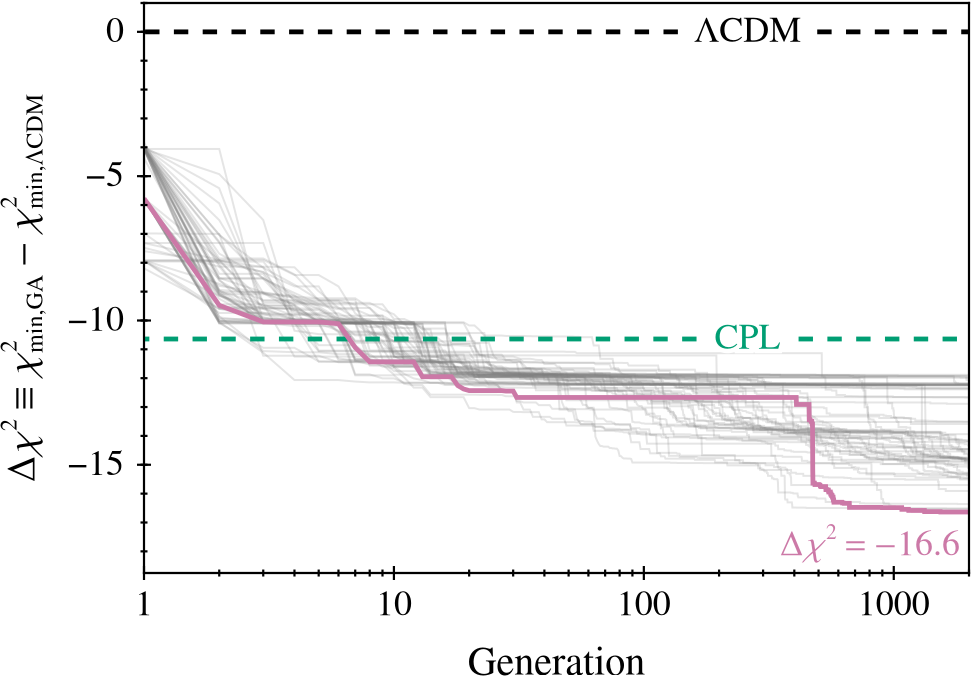

In [23]:
# Figure settings
fig = Figure(figure_padding=SCALE .* (0, axis_line_pt, 0, axis_line_pt))   # no outer margin: right and top keep only the frame line
ax = Axis(fig[1, 1], 
          xscale = log10, 
          xticks = ([1, 10, 100, 1000], ["1", "10", "100", "1000"]),   # plain numbers instead of 10^k
          xminorticks = IntervalsBetween(9, true),   # 2, 3, …, 9 × 10^k; mirror = true also fills 1000–2000
          yminorticks = -18:1:1,   # every unit
          xlabel="Generation", 
          ylabel=L"\Delta \chi^2 \equiv \chi_\mathrm{{min,GA}}^2 - \chi_{\mathrm{min},\Lambda\mathrm{CDM}}^2", 
          limits = ((1, 2000), (-18.75, 1)),   # best final Δχ² = -16.8, all runs below ΛCDM
          xgridvisible = false,
          ygridvisible = false
)

# ΛCDM: dashed line with a gap holding its label; the gap is symmetric in log10(generation).
# Both pieces are drawn from the gap outwards: the dash pattern starts at the first point, so each side of the label
# begins with a full dash
lcdm_label_gen, lcdm_gap_factor = 260.0, 1.9   # label centre and half-gap as a factor in generation
for (g1, g2) in ((lcdm_label_gen / lcdm_gap_factor, 1.0), (lcdm_label_gen * lcdm_gap_factor, 2000.0))
    lines!(ax, [g1, g2], [0.0, 0.0]; linestyle=:dash, color="black", linewidth = SCALE * line_pt)
end
text!(ax, lcdm_label_gen, 0.0; text = L"\Lambda\mathrm{CDM}", align = (:center, :center),
      fontsize = legend_pt)

# Load all runs
for i in eachindex(results)
    lines!(ax, generations[i], chi2_evolution[i] .- chi2_LCDM;
           color=(:gray, 0.2), linewidth = SCALE * 0.5 * UNITS_PER_POINT)   # 0.5 pt, the APS minimum
end

# CPL: χ² at the MAP of the newest binning/ Nautilus chain (on the GA's likelihoods), drawn like ΛCDM in the w(z) green.
# Drawn after the runs, so the line and its label sit on top of them
cpl_color = "#009E73"
Δχ2_CPL = chi2_CPL - chi2_LCDM
cpl_gap_factor = 1.6   # narrower than ΛCDM's: "CPL" is a shorter label
cpl_gap = (lcdm_label_gen / cpl_gap_factor, lcdm_label_gen * cpl_gap_factor)
for (g1, g2) in ((cpl_gap[1], 1.0), (cpl_gap[2], 2000.0))   # from the gap outwards, as ΛCDM
    lines!(ax, [g1, g2], fill(Δχ2_CPL, 2); linestyle=:dash, color=cpl_color, linewidth = SCALE * line_pt)
end
# White halo around the glyphs only, so the runs stay visible. Cairo strokes over the fill, so the halo is a
# separate white copy underneath and the green label is drawn on top without a stroke
cpl_label = (text = L"\mathrm{CPL}", align = (:center, :center), fontsize = legend_pt)
text!(ax, lcdm_label_gen, Δχ2_CPL; cpl_label..., color = :white, strokecolor = :white, strokewidth = 3 * SCALE)
text!(ax, lcdm_label_gen, Δχ2_CPL; cpl_label..., color = cpl_color)

# Best run
lines!(ax, generation_nolocal, chi2_nolocal .- chi2_LCDM;
       color="#CC79A7", linewidth=SCALE * line_pt)   # pink of the best individual in the GAME figures

# Indicate best runs χ²
text!(
    ax,
    gen_best,
    chi2_best .- chi2_LCDM;
    text = L"\Delta \chi^2 = {-}%$(abs(round(chi2_best .- chi2_LCDM, digits=1)))",
    align = (:right, :bottom),
    offset = (-3, -0.075 * SCALE * UNITS_PER_INCH * height_inches),
    color = "#CC79A7",
    fontsize = legend_pt,
)

save(joinpath(figures_dir, "chi2_evolution.pdf"), fig)
fig

### `GAME` average

We apply the `GAME` procedure to obtain some kind of weighted average plots. What `GAME` does is the following. Once the function is fitted *to the data* (not our approach, which is at the Lagrangian density level) and ran for $N_{\rm conf}$ different configurations, a weighted is associated to each best individual in each configuration:

$$
w_j =
\frac{\exp\left[ -\frac{1}{2}\left( \chi_j^2 - \chi_{\rm min}^2\right) \right]}{\sum_{k=1}^{N_{\rm conf}} \exp\left[ -\frac{1}{2}\left( \chi_k^2 - \chi_{\rm min}^2\right) \right]}
,\qquad
\sum_{j=1}^{N_{\rm conf}} w_j = 1.
$$

In practice, they use a different fitness function. The `GAME` average function is then computed as

$$
f_{\rm GAME}(x) =
\sum_{j=1}^{N_{\rm conf}} w_j \cdot f_{j,{\rm GA}}(x)
,\qquad
\sigma_{\rm ens}^2 =
\sum_{j=1}^{N_{\rm conf}} w_j^2 \left( f_{j,{\rm GA}}(x) - f_{\rm GAME}(x) \right)^2.
$$

We now follow this heuristic and apply it to the functions that we aim to plot. Specifically, the $f_j$ will be the observables (equation of state $w$, $\mu_G$, etc) that are computed from the best-fit functions at the level of the Lagrangian (i.e. the $F(\Phi)$ and $U(\Phi)$ functions), and follow the same recipy using the equations shown above.

According to the `GAME` paper, an additional "path-integral" error would be missing, which could be obtained from other techniques such as Bootstrap Monte Carlo, but I am not really sure how this would be applied in our setting.

#### Implementation

- **Re-polished fits.** Most run winners stop at the GA's 2 s Nelder–Mead time limit. The χ² differences
  that set the weights are $\mathcal{O}(0.1\text{–}1)$, so each winner is first re-fitted: Nelder–Mead is restarted
  from its stored best fit for up to `game_polish.rounds` rounds of `game_polish.time_limit` seconds. Only the
  numeric constants and the cosmological parameters change, never the trees. The polished χ² and parameters feed
  both the weights and the curves. The result is cached in `game_cache_path`; it is recomputed when the
  winners or `game_polish` change. Delete the file to force a re-polish.
- **Weights.** Eq. (2.19) over all $N_{\rm conf}$ winners (one per run). There is no $\Delta\chi^2$ cut: the
  weights already suppress poor fits. $N_{\rm eff} = 1/\sum_j w_j^2$ is printed.
- **Ensemble error.** `game_σ_power = 2` gives $\sigma_{\rm ens}^2 = \sum_j w_j^2 (f_j - f_{\rm GAME})^2$ as in
  the paper. For near-uniform weights this is roughly the scatter divided by $\sqrt{N_{\rm eff}}$, an error on the
  weighted mean. `game_σ_power = 1` gives the weighted scatter $\sum_j w_j (f_j - f_{\rm GAME})^2$ instead (the
  law of total variance).
- **Not yet included:** the path-integral term $\delta f_{\rm PI}$. The bands are $\pm 1\sigma$ and $\pm 2\sigma$ of
  $\sigma_{\rm ens}$ alone. The pink line is the polished best-χ² individual (the paper's "baseline GA").

In [24]:
# Re-polish every run winner before weighting (most stopped at the GA's 2 s optimizer time limit)
game_polish = (time_limit=1.0, rounds=1, tol=1e-3)   # seconds per Nelder–Mead round; stop once a round gains < tol in χ²

"""
    polish_candidate(candidate, likelihoods, cache, config; time_limit, rounds, tol) -> (FittedCandidate, χ²_restart)

Re-fit the constants and cosmological parameters of `candidate`, starting from its stored best fit. Nelder–Mead
(`fit_once!` with the run's minimizer settings and a longer `time_limit`) is restarted for at most `rounds` rounds;
a round is kept only when it lowers χ², and the loop stops once a round gains less than `tol`. The trees are copied,
so `candidate` is not modified; without any gain a copy of it is returned. Also returns χ² re-evaluated at the stored
best fit, which should reproduce `candidate.chi2`.

Generated with Claude Opus 5.5.
"""
function polish_candidate(candidate::FittedCandidate, likelihoods, cache, config::RunConfig;
    time_limit=10.0, rounds=3, tol=1e-3)
    ind = copy_fitted(candidate).individual
    spec = build_parameter_spec(ind, likelihoods)
    spec.param_names == candidate.param_names ||
        error("parameters $(spec.param_names) differ from the stored $(candidate.param_names)")
    saved = config.minimizer
    settings = MinimizeSettings(
        time_limit, saved.g_tol, saved.max_prune_iterations,
        saved.fisher_fd_factor, saved.fisher_negative_tol,
        saved.invalid_objective, saved.rejection_objective,
        saved.recovery_enabled, saved.recovery_max_probes,
        saved.recovery_time_fraction,
    )
    objective = build_joint_objective(build_minimization_context(likelihoods, cache), spec, ind, settings)

    # Stored best fit: cosmological parameters, then the F and U constants (the objective's order)
    x = vcat(candidate.best_params, get_optimizable_constants(ind.F), get_optimizable_constants(ind.U))
    chi2_restart = 2 * objective(x)

    chi2, best = chi2_restart, nothing
    for _ in 1:rounds
        fit = fit_once!(objective, spec, ind, x, settings)
        (fit.accepted && 2 * fit.objective_value < chi2) || break
        gain = chi2 - 2 * fit.objective_value
        x, chi2, best = fit.x_opt, 2 * fit.objective_value, fit
        gain < tol && break
    end
    best === nothing && return copy_fitted(candidate), chi2_restart

    lock_best_fit!(ind, spec, best.x_opt)   # a rejected later round may have left other constants in the trees
    result = make_result(ind, spec, best, Float64[]; status=:disabled)
    return fitted_candidate(result, config.penalty), chi2_restart
end

"""
    save_polished(path, digests, settings, polished, chi2_restart)

Write the polished winners to the HDF5 cache `path`, keyed by the digests of the stored winners and the polish
`settings` (a NamedTuple, stored as attributes).

Generated with Claude Opus 5.5.
"""
function save_polished(path, digests, settings, polished, chi2_restart)
    h5open(path, "w") do file
        write(file, "stored_digest", digests)
        write(file, "chi2_restart", chi2_restart)
        for (key, value) in pairs(settings)
            HDF5.attributes(file)[String(key)] = value
        end
        write_candidates(create_group(file, "polished"), polished)
    end
    return path
end

"""
    load_polished(path, digests, settings) -> (polished, chi2_restart) or nothing

Read the cache written by `save_polished`. Returns `nothing` when the file is missing or was made from other
winners or other polish settings.

Generated with Claude Opus 5.5.
"""
function load_polished(path, digests, settings)
    isfile(path) || return nothing
    h5open(path, "r") do file
        attrs = HDF5.attributes(file)
        haskey(file, "stored_digest") && read(file, "stored_digest") == digests || return nothing
        all(haskey(attrs, String(key)) && read(attrs[String(key)]) == value for (key, value) in pairs(settings)) ||
            return nothing
        return (polished=read_candidates(file["polished"]), chi2_restart=read(file, "chi2_restart"))
    end
end

# χ² values are only comparable when every run used the same likelihoods
@assert allequal(r.config.ga.likelihoods for r in results)

game_stored_digests = candidate_digest.(best_individuals)
game_cached = load_polished(game_cache_path, game_stored_digests, game_polish)
if game_cached === nothing
    n_polish = length(best_individuals)
    @printf("Polishing %d fits on %d threads (at most %.0f s each, about %.1f min in the worst case)\n",
        n_polish, Threads.nthreads(), game_polish.rounds * game_polish.time_limit,
        cld(n_polish, Threads.nthreads()) * game_polish.rounds * game_polish.time_limit / 60)
    game_likes, game_caches = build_thread_resources(load_likelihoods(results[1].config.ga.likelihoods))
    game_polished = Vector{FittedCandidate}(undef, n_polish)
    game_chi2_restart = fill(NaN, n_polish)
    with_logger(SimpleLogger(stderr, Logging.Error)) do
        # One cache and likelihood copy per thread, indexed by threadid(): the :static schedule is required
        Threads.@threads :static for i in 1:n_polish
            thread = Threads.threadid()
            game_polished[i], game_chi2_restart[i] = polish_candidate(best_individuals[i],
                game_likes[thread], game_caches[thread], results[i].config; game_polish...)
        end
    end
    save_polished(game_cache_path, game_stored_digests, game_polish, game_polished, game_chi2_restart)
else
    game_polished, game_chi2_restart = game_cached.polished, game_cached.chi2_restart
    println("Loaded the polished fits from ", game_cache_path)
end

game_chi2_stored = [c.chi2 for c in best_individuals]
game_gain = game_chi2_stored .- [c.chi2 for c in game_polished]
@printf("Stored fits re-evaluated: max |χ²_restart − χ²_stored| = %.2e\n",
    maximum(abs.(game_chi2_restart .- game_chi2_stored)))
@printf("Polishing lowered χ² in %d of %d fits (median gain %.3f, max %.3f)\n",
    count(>(0), game_gain), length(game_gain), median(game_gain), maximum(game_gain))
@printf("Best χ²: %.3f (stored) → %.3f (polished)\n",
    minimum(game_chi2_stored), minimum(c.chi2 for c in game_polished))

Loaded the polished fits from runs/grid_main/game_polished.h5
Stored fits re-evaluated: max |χ²_restart − χ²_stored| = 4.55e-13
Polishing lowered χ² in 55 of 64 fits (median gain 0.006, max 0.120)
Best χ²: 1571.742 (stored) → 1571.738 (polished)


In [25]:
"""
    game_weights(chi2) -> Vector{Float64}

Normalised GAME weights w_j ∝ exp[-(χ²_j - χ²_min)/2] (Peronaci et al. 2026, eq. 2.19).

Generated with Claude Opus 5.5.
"""
function game_weights(chi2::AbstractVector{<:Real})
    w = exp.(-0.5 .* (chi2 .- minimum(chi2)))
    return w ./ sum(w)
end

"""
    game_average(M, w; power=2) -> (mean, σ)

Weighted mean Σ_j w_j f_j (eq. 2.25) and ensemble error σ = sqrt(Σ_j w_j^power (f_j - mean)²) of the curves stored
as the rows of `M`, at every column. `power=2` is eq. 2.26 of the paper; `power=1` is the weighted scatter. Non-finite
values are skipped and the weights renormalised over the remaining rows; columns without any finite value are `NaN`.

Generated with Claude Opus 5.5.
"""
function game_average(M::AbstractMatrix, w::AbstractVector; power::Real=2)
    μ, σ = fill(NaN, size(M, 2)), fill(NaN, size(M, 2))
    for j in axes(M, 2)
        keep = isfinite.(M[:, j])
        any(keep) || continue
        wk = w[keep] ./ sum(w[keep])
        f = M[keep, j]
        μ[j] = sum(wk .* f)
        σ[j] = sqrt(sum(wk .^ power .* (f .- μ[j]) .^ 2))
    end
    return μ, σ
end

"""
    observable_curves(pool, z) -> (curves, solved)

Observables of every `(run index, candidate)` pair in `pool` on the grid `z`, one row per candidate and one
background solve each: `w` (w_ST), `mu` (μ_G), `F`, `FPhi2` ((dF/dΦ)²) and `U` (U0 + U). Candidates whose background fails to solve are dropped; `solved` marks the kept ones.

Generated with Claude Opus 5.5.
"""
function observable_curves(pool, z)
    names = (:w, :mu, :F, :FPhi2, :U)
    curves = NamedTuple{names}(ntuple(_ -> fill(NaN, length(pool), length(z)), length(names)))
    solved = falses(length(pool))
    for (k, (i, c)) in enumerate(pool)
        bg = try
            reconstruct_background(c, results[i].config)
        catch err
            err isa solve_errors || rethrow()
            continue
        end
        for (j, zi) in enumerate(z)
            curves.w[k, j] = w_ST(bg, zi)
            curves.mu[k, j] = μ_G(bg, zi)
            curves.F[k, j], curves.FPhi2[k, j], curves.U[k, j] = field_functions(bg, zi)
        end
        solved[k] = true
    end
    return map(M -> M[solved, :], curves), solved
end

# Failures of the background solve that drop a candidate; anything else is a real error
solve_errors = Union{BackgroundSolveError, InitialPhiSolveError, PhysicalDomainError,
                     ShootingSolveError, DomainError}
z_ens = range(0, 2.5; length=2000)

# One polished winner per run, weighted by its χ²
game_pool = [(i, c) for (i, c) in enumerate(game_polished) if c.accepted]
game_curves, game_solved = observable_curves(game_pool, z_ens)
game_pool = game_pool[game_solved]
game_w = game_weights([c.chi2 for (_, c) in game_pool])
game_best = argmax(game_w)   # row of the polished best-χ² individual

game_σ_power = 1   # 2: σ_ens of eq. 2.26 (w_j²); 1: weighted scatter (w_j)
game = map(M -> game_average(M, game_w; power=game_σ_power), game_curves)

@printf("Solved %d of %d backgrounds; N_eff = 1/Σw² = %.1f\n", length(game_pool), length(game_solved),
    1 / sum(abs2, game_w))
println("Largest weights:")
for k in sortperm(game_w; rev=true)[1:min(10, length(game_w))]
    i, c = game_pool[k]
    @printf("  run %3d  w = %.4f  Δχ² = %.3f  χ² = %.3f (stored %.3f)\n",
        i, game_w[k], c.chi2 - game_pool[game_best][2].chi2, c.chi2, best_individuals[i].chi2)
end

Solved 64 of 64 backgrounds; N_eff = 1/Σw² = 44.1
Largest weights:
  run  61  w = 0.0462  Δχ² = 0.000  χ² = 1571.738 (stored 1571.742)
  run  48  w = 0.0438  Δχ² = 0.107  χ² = 1571.845 (stored 1571.846)
  run  34  w = 0.0433  Δχ² = 0.128  χ² = 1571.866 (stored 1571.869)
  run  12  w = 0.0402  Δχ² = 0.279  χ² = 1572.017 (stored 1572.017)
  run  47  w = 0.0321  Δχ² = 0.729  χ² = 1572.467 (stored 1572.472)
  run  51  w = 0.0290  Δχ² = 0.933  χ² = 1572.671 (stored 1572.673)
  run  11  w = 0.0269  Δχ² = 1.084  χ² = 1572.821 (stored 1572.866)
  run  38  w = 0.0260  Δχ² = 1.151  χ² = 1572.889 (stored 1572.903)
  run  31  w = 0.0256  Δχ² = 1.181  χ² = 1572.919 (stored 1572.925)
  run   9  w = 0.0248  Δχ² = 1.246  χ² = 1572.984 (stored 1572.997)


In [26]:
show_game_best = true   # also draw the polished best-χ² individual
ensemble_color = RGBf(48/255, 132/255, 196/255)

"""
    plot_game!(ax, z, (μ, σ))

Draw the GAME mean `μ` with its ±1σ and ±2σ ensemble bands on `ax`.

Generated with Claude Opus 5.5.
"""
function plot_game!(ax, z, (μ, σ)::Tuple)
    # Outer band as two strips around the 1σ band, so the two shades stay distinct
    band!(ax, z, μ .- 2 .* σ, μ .- σ; color=(ensemble_color, band_alpha))
    band!(ax, z, μ .+ σ, μ .+ 2 .* σ; color=(ensemble_color, band_alpha))
    band!(ax, z, μ .- σ, μ .+ σ; color=(ensemble_color, 2.2 * band_alpha))
    lines!(ax, z, μ; color=ensemble_color)
    return ax
end

plot_game!

### `GAME` figures

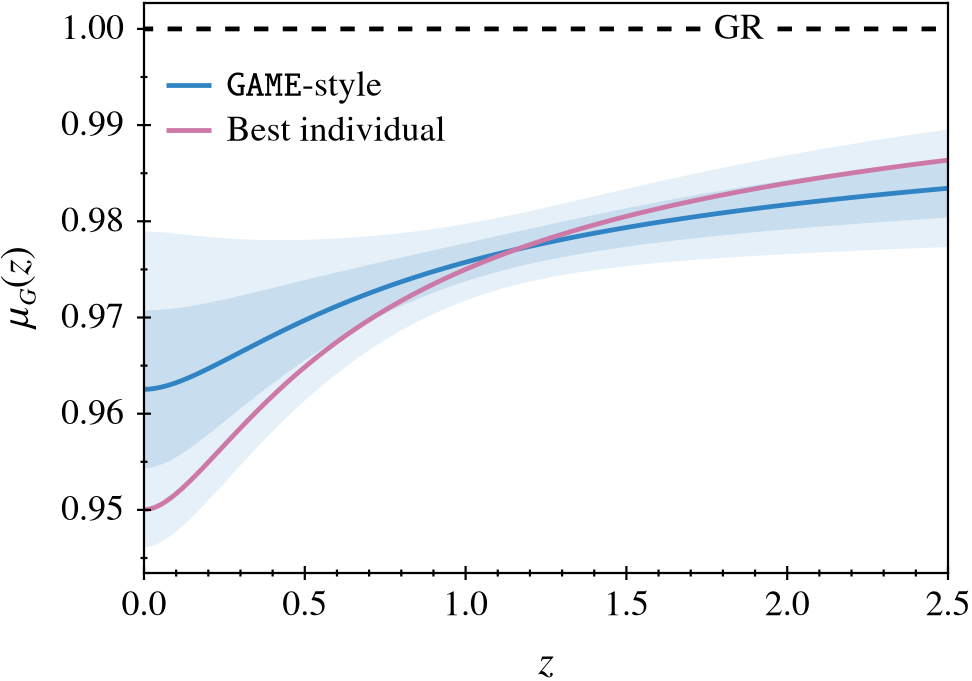

In [27]:
fig_mu_game = Figure(figure_padding=SCALE .* (0.01 * tick_label_pt, 0.65 * tick_label_pt, 0, axis_line_pt))   # no outer margin: right keeps the overhanging "2.5", top the frame line
ax = Axis(fig_mu_game[1, 1],
    xlabel=L"$z$",
    ylabel=L"\mu_G(z)",
    limits=((minimum(z_ens), maximum(z_ens)), nothing),
    xgridvisible=false,
    ygridvisible=false,
    yticks=0.90:0.01:1.10,   # every 0.01, so 0.95, 0.97 and 0.99 are labelled too
    yminorticks=IntervalsBetween(2)
)

μ_scale = 1

# GR (μ_G = 1): dashed line with a gap holding its label, as in the stacked F panel; no legend entry
mu_gr_label_z, mu_gr_gap_halfwidth = 1.85, 0.12   # centre of the label and half the gap, in z
# Both pieces are drawn from the gap outwards: the dash pattern starts at the first point, so each side of the label
# begins with a full dash
for (z1, z2) in ((mu_gr_label_z - mu_gr_gap_halfwidth, first(z_ens)), (mu_gr_label_z + mu_gr_gap_halfwidth, last(z_ens)))
    lines!(ax, [z1, z2], [1.0, 1.0]; color=:black, linestyle=:dash, linewidth=SCALE * line_pt)
end
text!(ax, mu_gr_label_z, 1.0; text=L"\mathrm{GR}", align=(:center, :center), fontsize=SCALE * legend_pt)

plot_game!(ax, z_ens, (game.mu[1] .* μ_scale, game.mu[2] .* μ_scale))   # best individual drawn below
show_game_best && lines!(ax, z_ens, game_curves.mu[game_best, :] .* μ_scale; color="#CC79A7", linewidth=SCALE * line_pt)

# Explicit legend handles, as in the w(z) figure
legend_patchsize = (SCALE * 15, SCALE * 12)
axislegend(ax,
    [LineElement(; color=ensemble_color, linewidth=SCALE * line_pt),
     LineElement(; color="#CC79A7", linewidth=SCALE * line_pt)],
    [rich(rich("GAME"; font=paper_tt_font), "-style"), "Best individual"];
    #position=(1.05, 0.), framevisible=false, backgroundcolor=:transparent, patchsize=legend_patchsize,
    position=(-0.05, 0.9), framevisible=false, backgroundcolor=:transparent, patchsize=legend_patchsize,
    rowgap=SCALE * 3)

save(joinpath(figures_dir, "mu_G_game.pdf"), fig_mu_game)
fig_mu_game

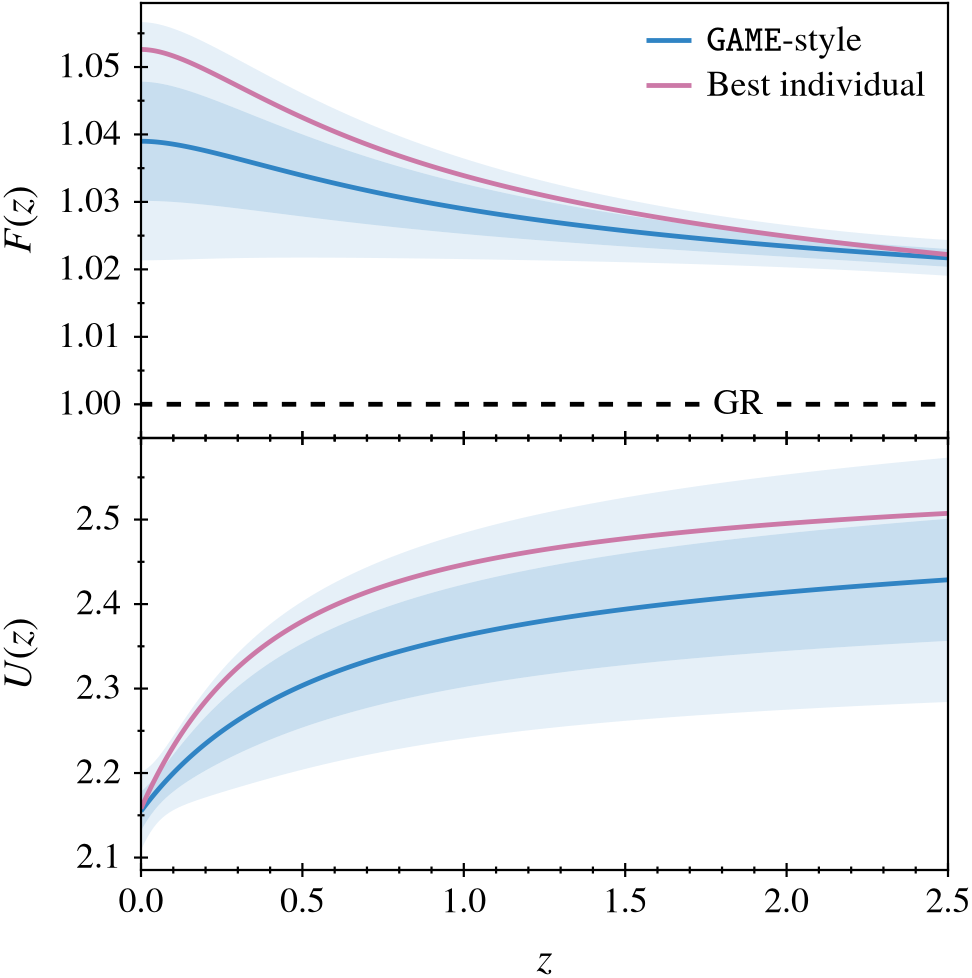

In [28]:
# F and U stacked on a shared z axis, in the style of the single GAME panels above
stack_height_inches = 3.4   # was 4.6 for three panels; keeps each panel about the same height
fig_FU_game = Figure(size=(SCALE * UNITS_PER_INCH * width_inches, SCALE * UNITS_PER_INCH * stack_height_inches),
    figure_padding=SCALE .* (0, 0.65 * tick_label_pt, 0, axis_line_pt))   # no outer margin, as in the single panels

# GR reference of the F panel: (value, text, centre of the label in z, half width of the gap in the line that holds it)
gr_reference = (1.0, L"\mathrm{GR}", 1.85, 0.12)   # F = 1 holds for any GR model, not only ΛCDM
stack_panels = [   # (y label, GAME average, curves, reference line or nothing, y ticks, y minor intervals,
    #  lower y limit or nothing for automatic)
    (L"F(z)", game.F, game_curves.F, gr_reference, 0.95:0.01:1.10, 2, 0.995),   # every 0.01, so 1.01 to 1.05 are all labelled
    (L"U(z)", game.U, game_curves.U, nothing, Makie.automatic, 2, nothing),
]
stack_axes = map(enumerate(stack_panels)) do (k, (label, average, curves, reference, yticks, yminor, ylow))
    ax = Axis(fig_FU_game[k, 2],
        xlabel=L"$z$",
        limits=((minimum(z_ens), maximum(z_ens)), (ylow, nothing)),   # upper y limit automatic
        xgridvisible=false,
        ygridvisible=false,
        yticks=yticks,
        yminorticks=IntervalsBetween(yminor),
        xticksmirrored=k > 1   # two-sided ticks on the boundary above: mirrored ticks are centred on it and take no layout space
    )
    if k < length(stack_panels)   # z labels on the bottom panel only
        # Ticks stay visible, since the mirrored ones of the panel below need them; a zero bottom protrusion keeps them
        # from opening a gap
        hidexdecorations!(ax; ticks=false, minorticks=false)
        ax.alignmode = Mixed(bottom=Protrusion(0))
    end
    if !isnothing(reference)
        # Dashed line with a gap holding its label, as the ΛCDM line in the χ² figure; no legend entry
        value, text, label_z, gap = reference
        # Both pieces from the gap outwards, so each side of the label begins with a full dash
        for (z1, z2) in ((label_z - gap, first(z_ens)), (label_z + gap, last(z_ens)))
            lines!(ax, [z1, z2], [value, value]; color=:black, linestyle=:dash, linewidth=SCALE * line_pt)
        end
        text!(ax, label_z, value; text=text, align=(:center, :center), fontsize=SCALE * legend_pt)
    end
    plot_game!(ax, z_ens, average)   # best individual drawn below
    show_game_best && lines!(ax, z_ens, curves[game_best, :]; color="#CC79A7", linewidth=SCALE * line_pt)
    # y labels in their own column, so they line up although the tick labels differ in width
    Label(fig_FU_game[k, 1], label; rotation=π / 2, fontsize=SCALE * axis_label_pt, tellheight=false)
    ax
end
linkxaxes!(stack_axes...)
rowgap!(fig_FU_game.layout, 0)
colgap!(fig_FU_game.layout, SCALE * label_padding_pt)

# Explicit legend handles, as in the single panels; only in the top panel
legend_patchsize = (SCALE * 15, SCALE * 12)
axislegend(stack_axes[1],
    [LineElement(; color=ensemble_color, linewidth=SCALE * line_pt),
     LineElement(; color="#CC79A7", linewidth=SCALE * line_pt)],
    [rich(rich("GAME"; font=paper_tt_font), "-style"), "Best individual"];
    position=(1.05, 1.0), framevisible=false, backgroundcolor=:transparent, patchsize=legend_patchsize,
    rowgap=SCALE * 3)

save(joinpath(figures_dir, "F_and_U_game.pdf"), fig_FU_game)
fig_FU_game

In [ ]:
# CPL and binned posteriors with the GAME average of w_ST (±1σ and ±2σ of σ_ens, as in plot_game!)
fig_w_game_desi = Figure(figure_padding=SCALE .* (0, 0.65 * tick_label_pt, 0, axis_line_pt))   # no outer margin: right keeps the overhanging "2.5", top the frame line
ax = Axis(fig_w_game_desi[1, 1],
    xlabel=L"$z$",
    ylabel=L"w(z)",
    limits=((0, 2.5), (-2.2, -0.4)),
    xgridvisible=false,
    ygridvisible=false,
    yminorticks=IntervalsBetween(5)
)

hlines!(ax, [-1.0]; color=:black, linestyle=:dash, linewidth=SCALE * line_pt)


z_w = range(0, 3; length=500)
plot_w_cpl!(ax, cpl_chain; z=z_w)
Q_cpl = w_quantiles(cpl_chain, collect(Float64, z_w); probs=[0.025, 0.16, 0.5, 0.84, 0.975])
cpl_dash = (color="#009E73", linestyle=:dash, linewidth=0.5 * SCALE * line_pt)   # ±1σ
cpl_dot = (color="#009E73", linestyle=:dot, linewidth=0.5 * SCALE * line_pt)     # ±2σ
# lines!(ax, z_w, Q_cpl[2, :]; cpl_dash...)   # +1σ (16%)
# lines!(ax, z_w, Q_cpl[4, :]; cpl_dash...)   # -1σ (84%)
# lines!(ax, z_w, Q_cpl[1, :]; cpl_dot...)    # +2σ (2.5%)
# lines!(ax, z_w, Q_cpl[5, :]; cpl_dot...)    # -2σ (97.5%)

plot_game!(ax, z_ens, game.w)   # best individual drawn below
show_game_best && lines!(ax, z_ens, game_curves.w[game_best, :]; color="#CC79A7", linewidth=SCALE * line_pt)
plot_w_binned!(ax, binned_chain; color="#D55E00", last_bin_center=2.3, last_bin_right=2.43, violin_width=0.15,
    label=nothing, binned_style...)   # no auto legend entry: the binned glyph is drawn below with its caps

# Explicit legend handles
legend_patchsize = (SCALE * 15, SCALE * 12)   # shorter patches: tighter rows (height 15 before)
axislegend(ax,
    [LineElement(; color=ensemble_color, linewidth=SCALE * line_pt),
     LineElement(; color="#CC79A7", linewidth=SCALE * line_pt),
     LineElement(; color="#009E73", linewidth=SCALE * line_pt),
     errorbar_legend_handle("#D55E00"; linewidth=binned_style.linewidth, markersize=binned_style.markersize,
         whiskerwidth=binned_style.whiskerwidth, patchsize=legend_patchsize)],
    [rich(rich("GAME"; font=paper_tt_font), "-style"), "Best individual", "CPL",
     L"\mathrm{Binning}"];
    position=(-0.05, 0.), framevisible=false, backgroundcolor=:transparent, patchsize=legend_patchsize,
    rowgap=SCALE * 3)   # empty strip above the curves

save(joinpath(figures_dir, "eos_game_desi.pdf"), fig_w_game_desi, px_per_unit=300 / 96)
fig_w_game_desi

In [ ]:
"""
    H_cpl(z, Om0, h, w0, wa) -> Float64

H(z) in km/s/Mpc of flat CPL, with the radiation of the GA and of the chains (`radiation_density_parameter`):
E² = Ω_r (1+z)⁴ + Ω_m (1+z)³ + Ω_DE (1+z)^{3(1+w0+wa)} exp(-3 wa z/(1+z)), with Ω_DE = 1 - Ω_m - Ω_r.

Generated with Claude Opus 5.5.
"""
function H_cpl(z::Real, Om0::Real, h::Real, w0::Real, wa::Real)
    Or0 = radiation_density_parameter(Float64(h))
    Ode = (1 - Om0 - Or0) * (1 + z)^(3 * (1 + w0 + wa)) * exp(-3 * wa * z / (1 + z))
    return 100 * h * sqrt(Or0 * (1 + z)^4 + Om0 * (1 + z)^3 + Ode)
end

z_H = z_ens
H_lcdm = H.(Ref(background_lcdm), z_H)
H_cpl_map = H_cpl.(z_H, (cpl_chain.map_params[name] for name in ("Om0", "h", "w0", "wa"))...)

# One curve per polished winner, in the order of game_w
H_game_curves = fill(NaN, length(game_pool), length(z_H))
for (k, (i, c)) in enumerate(game_pool)
    bg = reconstruct_background(c, results[i].config)
    H_game_curves[k, :] = H.(Ref(bg), z_H)
end
game_H = game_average(H_game_curves, game_w; power=game_σ_power)

for z in (0.0, 0.5, 1.0, 2.5)
    j = argmin(abs.(z_H .- z))
    @printf("z = %.1f: H ΛCDM %.2f   CPL %.2f   GAME-style %.2f ± %.2f   best %.2f km/s/Mpc\n", z_H[j], H_lcdm[j],
        H_cpl_map[j], game_H[1][j], game_H[2][j], H_game_curves[game_best, j])
end

rel(Hz) = 100 .* (Hz ./ H_lcdm .- 1)   # per cent difference from ΛCDM
comoving(Hz) = Hz ./ (1 .+ z_H)          # H/(1+z) = ȧ, in km/s/Mpc

In [ ]:
# H(z)/(1+z) as a single panel of the standard size, with ΔH/H_ΛCDM in an inset. Uses the curves of the cell above
# (H_lcdm, H_cpl_map, game_H, H_game_curves, comoving, rel)
inset_tick_pt = 8.0 * UNITS_PER_POINT    # 1 pt below the main tick labels
inset_label_pt = 9.0 * UNITS_PER_POINT
inset_ymin = -1.2   # lower y limit of the inset, below the CPL minimum
inset_box = (width=0.48, height=0.42, halign=0.36, valign=0.96)   # size as fractions of the main axis, position in it
# Room below the rising branch for the legend and above the curves for the inset (nothing: automatic)
H_inset_ylims = (58.5, 72.5)

fig_H_inset = Figure(figure_padding=SCALE .* (0, 0.65 * tick_label_pt, 0, axis_line_pt))   # as the single GAME panels
ax = Axis(fig_H_inset[1, 1],
    xlabel=L"$z$",
    ylabel=L"H(z)/(1+z)\;(\mathrm{km\,s^{-1}\,Mpc^{-1}})",
    limits=((minimum(z_H), maximum(z_H)), H_inset_ylims),
    xgridvisible=false,
    ygridvisible=false,
    yminorticks=IntervalsBetween(5),
)
lines!(ax, z_H, comoving(H_lcdm); color=:black, linestyle=:dash, linewidth=SCALE * line_pt)
lines!(ax, z_H, comoving(H_cpl_map); color=cpl_color, linewidth=SCALE * line_pt)
plot_game!(ax, z_H, (comoving(game_H[1]), comoving(game_H[2])))   # best individual drawn below
show_game_best && lines!(ax, z_H, comoving(H_game_curves[game_best, :]); color="#CC79A7", linewidth=SCALE * line_pt)

legend_patchsize = (SCALE * 15, SCALE * 12)
axislegend(ax,
    [LineElement(; color=:black, linestyle=:dash, linewidth=SCALE * line_pt),
     LineElement(; color=cpl_color, linewidth=SCALE * line_pt),
     LineElement(; color=ensemble_color, linewidth=SCALE * line_pt),
     LineElement(; color="#CC79A7", linewidth=SCALE * line_pt)],
    [L"\Lambda\mathrm{CDM}", "CPL", rich(rich("GAME"; font=paper_tt_font), "-style"), "Best individual"];
    position=(1.05, 0.0), framevisible=false, backgroundcolor=:transparent, patchsize=legend_patchsize,
    rowgap=SCALE * 3)

# Inset: per cent difference from ΛCDM. Placed in the main axis' cell, sized relative to it, and lifted above the main
# plot in z so that its white background hides the curves underneath
ax_in = Axis(fig_H_inset[1, 1],
    width=Relative(inset_box.width), height=Relative(inset_box.height),
    halign=inset_box.halign, valign=inset_box.valign, tellwidth=false, tellheight=false,
    backgroundcolor=:white,
    xlabel="",   # z is read off the main axis
    ylabel=L"\Delta H/H\;(\%)",   # relative to ΛCDM: say so in the caption
    limits=((minimum(z_H), maximum(z_H)), (inset_ymin, nothing)),   # upper y limit automatic
    xgridvisible=false,
    ygridvisible=false,
    ylabelsize=SCALE * inset_label_pt,
    xticklabelsize=SCALE * inset_tick_pt,
    yticklabelsize=SCALE * inset_tick_pt,
    ylabelpadding=0.4 * SCALE * label_padding_pt,
    xticksize=0.85 * SCALE * tick_size_pt,
    yticksize=0.85 * SCALE * tick_size_pt,
    xminorticksize=0.45 * SCALE * tick_size_pt,
    yminorticksize=0.45 * SCALE * tick_size_pt,
    xticks=0:1:3,
    xminorticks=IntervalsBetween(2),
    yminorticks=IntervalsBetween(2),
)
translate!(ax_in.blockscene, 0, 0, 150)
hlines!(ax_in, [0.0]; color=:black, linestyle=:dash, linewidth=SCALE * line_pt)
lines!(ax_in, z_H, rel(H_cpl_map); color=cpl_color, linewidth=SCALE * line_pt)
plot_game!(ax_in, z_H, (rel(game_H[1]), 100 .* game_H[2] ./ H_lcdm))
show_game_best && lines!(ax_in, z_H, rel(H_game_curves[game_best, :]); color="#CC79A7", linewidth=SCALE * line_pt)

save(joinpath(figures_dir, "H_game.pdf"), fig_H_inset)
fig_H_inset